<a href="https://colab.research.google.com/github/andrada-fodor/ML-Seminar-FodorAndrada/blob/main/Fodor_Andrada_Tema_LP3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Temă LP3 — Preprocesarea datelor (Titanic)

**Timp de lucru: maximum 15 minute** · lucru individual

Aplicați tehnicile din LP3 pe un set de date nou: **Titanic** — informații despre pasagerii navei (vârstă, sex, preț bilet, port de îmbarcare, punte) și dacă au supraviețuit (`survived`).

| Sarcina | Tema | Timp |
| --- | --- | --- |
| 1 | Valori lipsă: diagnostic și eliminare pe bază de prag | ~3 min |
| 2 | Imputarea valorilor lipsă | ~3 min |
| 3 | Asimetrie și transformare logaritmică | ~3 min |
| 4 | Outlieri (regula IQR) | ~3 min |
| 5 | Encoding și scalare | ~3 min |

> 💡 Completați celulele marcate `# TODO`. Nu e nevoie de cod perfect — contează să înțelegeți ce face fiecare pas.

### Pregătire — rulați celula (nu necesită modificări)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

titanic = sns.load_dataset('titanic')
df = titanic[['survived', 'pclass', 'sex', 'age', 'fare', 'embarked', 'deck']].copy()
df.head()

,survived,pclass,sex,age,fare,embarked,deck
0,0,3,male,22.0,7.2500,S,NaN
1,1,1,female,38.0,71.2833,C,C
2,1,3,female,26.0,7.9250,S,NaN
3,1,1,female,35.0,53.1000,S,C
4,0,3,male,35.0,8.0500,S,NaN


## Sarcina 1 — Valori lipsă (~3 min)

**1.1** Calculați procentul de valori lipsă pentru fiecare coloană, sortat descrescător.

**1.2** Eliminați coloanele cu **mai mult de 50%** valori lipsă. Care coloană dispare?

In [2]:
# TODO 1.1 — procentul de valori lipsă pe coloană
print((df.isna().mean()*100).sort_values(ascending=False))
print("\n")

# TODO 1.2 — eliminați coloanele cu > 50% valori lipsă
df_clean = df.drop(columns=['deck'])
df_clean.head()

deck        77.216611
age         19.865320
embarked     0.224467
sex          0.000000
pclass       0.000000
survived     0.000000
fare         0.000000
dtype: float64




,survived,pclass,sex,age,fare,embarked
0,0,3,male,22.0,7.2500,S
1,1,1,female,38.0,71.2833,C
2,1,3,female,26.0,7.9250,S
3,1,1,female,35.0,53.1000,S
4,0,3,male,35.0,8.0500,S


## Sarcina 2 — Imputarea valorilor lipsă (~3 min)

**2.1** Imputați `age` cu **mediana** și `embarked` cu **valoarea cea mai frecventă** (modul).

**2.2** Verificați că nu mai există valori lipsă și comparați deviația standard a lui `age` înainte și după imputare. *(salvați înainte de imputare: `age_inainte = df['age'].copy()`)*

survived    0
pclass      0
sex         0
age         0
fare        0
embarked    0
dtype: int64


,inainte,dupa
std,14.526,13.02


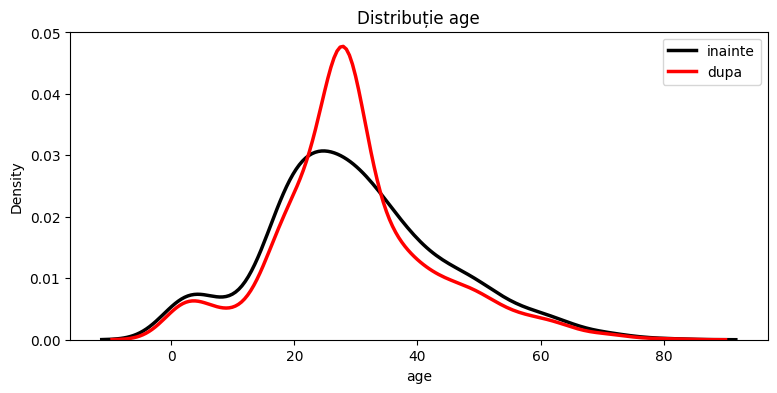

In [3]:
# TODO 2.1 — imputare age (mediană) și embarked (mod)
age_inainte = df['age'].copy()
df_clean['age'].fillna(df_clean['age'].median(), inplace=True)
df_clean['embarked'].fillna(df_clean['embarked'].mode()[0], inplace=True)

# TODO 2.2 — verificare + comparație deviație standard
print(df_clean.isna().sum())

tabel = pd.DataFrame({
    'inainte': age_inainte.dropna().agg(['std']),
    'dupa': df_clean['age'].agg(['std']),
}).round(3)
display(tabel)

plt.figure(figsize=(9, 4))
sns.kdeplot(age_inainte.dropna(), label='inainte', linewidth=2.5, color='black')
sns.kdeplot(df_clean['age'], label='dupa', linewidth=2.5, color='red')
plt.legend(); plt.title('Distribuție age'); plt.show()


## Sarcina 3 — Asimetrie și transformare logaritmică (~3 min)

**3.1** Calculați skewness-ul variabilei `fare`.

**3.2** Creați coloana `log_fare = np.log1p(fare)` și calculați skewness-ul ei. A ajutat transformarea?

**3.3** Desenați cele două histograme una lângă alta.

Skewness fare:  4.787316519674893
Skewness log_fare:  0.3949280095189306


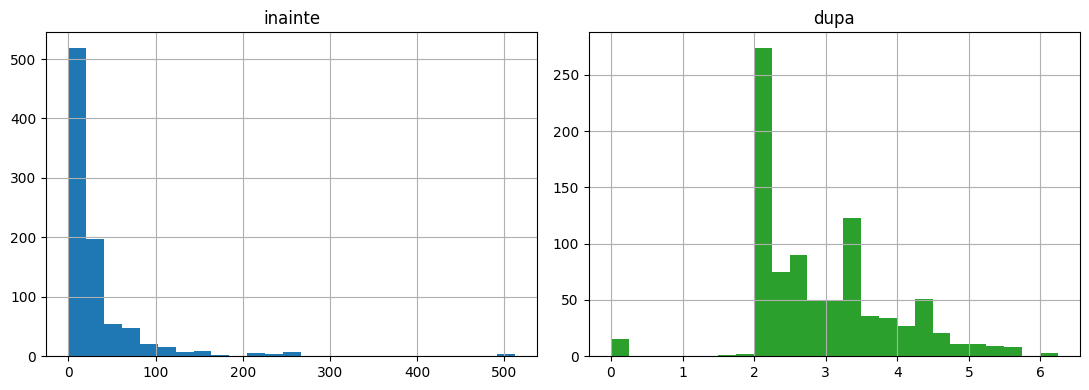

In [4]:
# TODO 3.1 — skewness fare
print("Skewness fare: ", df_clean['fare'].skew())


# TODO 3.2 — coloana log_fare + skewness
df_clean['log_fare'] = np.log1p(df_clean['fare'])
print("Skewness log_fare: ", df_clean['log_fare'].skew())

# TODO 3.3 — două histograme
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df_clean['fare'].hist(ax=axes[0], bins=25); axes[0].set_title('inainte')
df_clean['log_fare'].hist(ax=axes[1], bins=25, color='tab:green'); axes[1].set_title('dupa')
plt.tight_layout(); plt.show()

## Sarcina 4 — Outlieri cu regula IQR (~3 min)

**4.1** Calculați limitele `[Q1 − 1,5·IQR ; Q3 + 1,5·IQR]` pentru `fare` și numărați outlierii.

**4.2** Limitați (clip) valorile extreme într-o coloană nouă, `fare_capped`, și afișați maximul înainte și după.

In [9]:
# TODO 4.1 — limite IQR + număr de outlieri
def limite_iqr(serie, k=1.5):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

rezumat = []
for col in ['fare']:
    jos, sus = limite_iqr(df_clean[col])
    n_out = ((df_clean[col] < jos) | (df_clean[col] > sus)).sum()
    rezumat.append({'Variabilă': col, 'Limită inferioară': round(jos, 2), 'Limită superioară': round(sus, 2), 'Nr. outlieri': n_out})
print(pd.DataFrame(rezumat))
print('\n')

# TODO 4.2 — fare_capped (clip) + maxim înainte/după
jos, sus = limite_iqr(df_clean['fare'])
df_clean['fare_capped'] = df_clean['fare'].clip(lower=jos, upper=sus)

print("Maxim înainte :", df_clean['fare'].max())
print("Maxim după    :", df_clean['fare_capped'].max())

  Variabilă  Limită inferioară  Limită superioară  Nr. outlieri
0      fare             -26.72              65.63           116


Maxim înainte : 512.3292
Maxim după    : 65.6344


## Sarcina 5 — Encoding și scalare (~3 min)

**5.1** Aplicați One-Hot Encoding pe `sex` și `embarked` (cu `drop_first=True`, `dtype=int`).

**5.2** Standardizați `age` și `fare_capped` cu `StandardScaler`. Verificați că media ≈ 0 și deviația standard ≈ 1.

In [16]:
# TODO 5.1 — One-Hot Encoding pentru sex și embarked
dummies = pd.get_dummies(df_clean[['sex', 'embarked']], drop_first=True, dtype=int)
print("Formă după encoding:", dummies.shape)
print(dummies.head())
print('\n')
#df_clean = pd.concat([df_clean, dummies], axis=1)

# TODO 5.2 — StandardScaler pentru age și fare_capped + verificare medie/std
feat = ['age', 'fare_capped']
X_std = pd.DataFrame(StandardScaler().fit_transform(df_clean[feat]), columns=feat)
print("Standardizare — medie și deviație standard:")
display(X_std.describe().loc[['mean', 'std']].round(3))


Formă după encoding: (891, 3)
   sex_male  embarked_Q  embarked_S
0         1           0           1
1         0           0           0
2         0           0           1
3         0           0           1
4         1           0           1


Standardizare — medie și deviație standard:


,age,fare_capped
mean,0.000,0.000
std,1.001,1.001


## Întrebare de reflecție (1–2 propoziții)

*De ce am imputat `age`, dar am eliminat `deck`?*

*Răspunsul tău:* un motiv ar fi ca la deck lipseau ~77% din observatii, ceea ce e enorm, in timp ce la age doar ~20%